# 1 · Le modèle : ce qu'il lit, ce qu'il doit prédire

> **En bref**
> - **Le but** : prédire les débits de tout le réseau, et lire sur cette carte des débits où est la fuite.
> - **En entrée** : une heure de mesures (33 pressions, 3 débits, 82 compteurs, le réservoir T1,
>   la pompe) et ce que dit le modèle calibré sans fuite.
> - **La cible** : chaque conduite est coupée en deux ; le modèle prédit le débit des deux moitiés
>   (q1, q2), et la fuite est q1 − q2. Il prédit aussi une note « fuit / ne fuit pas ».
> - **Le modèle présenté, C**, prédit les deux. A ne prédit que les débits, B que la note.
> - Il apprend sur 763 épisodes simulés de 6 h.

In [1]:
import sys
sys.path.insert(0, "..")
from conduites import presentation as P

## 1. Les entrées

Le réseau a 905 conduites, mais il n'est mesuré qu'en quelques points.

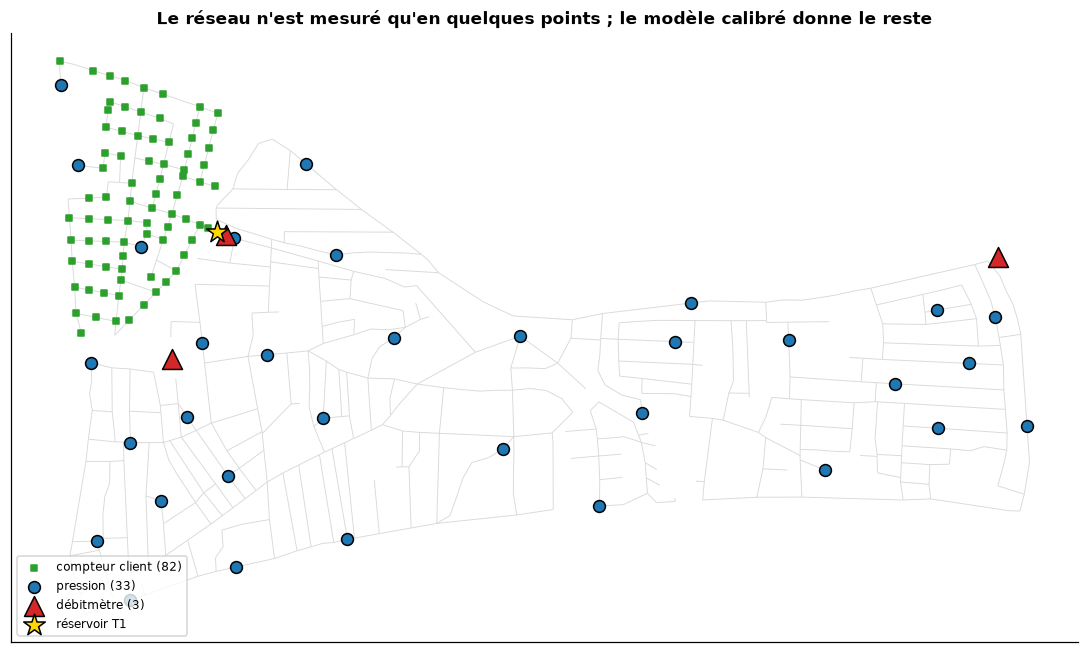

In [2]:
P.carte_des_mesures()

Chaque moitié de conduite reçoit, à chaque pas de 5 minutes, quatre sortes d'informations :

In [3]:
P.tableau_des_entrees()

,ce que c'est,où
1. le réseau fixe,"longueur, diamètre, rugosité, altitude et posi...",partout
2. les mesures,"pression (33 capteurs), débit (3 débitmètres),...",seulement aux capteurs
3. le modèle calibré sans fuite,"pression et débit de référence partout, demand...",partout
4. tiré de 2 et 3,résidu = pression mesurée − pression de référe...,aux 33 capteurs de pression


Le **modèle calibré** est notre modèle EPANET de L-Town, réglé sur les mesures, sans fuite. Le
**résidu** et le **dual** disent où les mesures s'écartent de ce modèle : c'est là qu'une fuite
laisse sa trace.

## 2. La cible

On coupe chaque conduite en son milieu et on y pose la fuite. Le modèle doit prédire le débit qui
entre dans la première moitié (q1) et celui qui sort de la seconde (q2). Sans fuite, q1 = q2 ; avec
une fuite, **q1 − q2 = la fuite**.

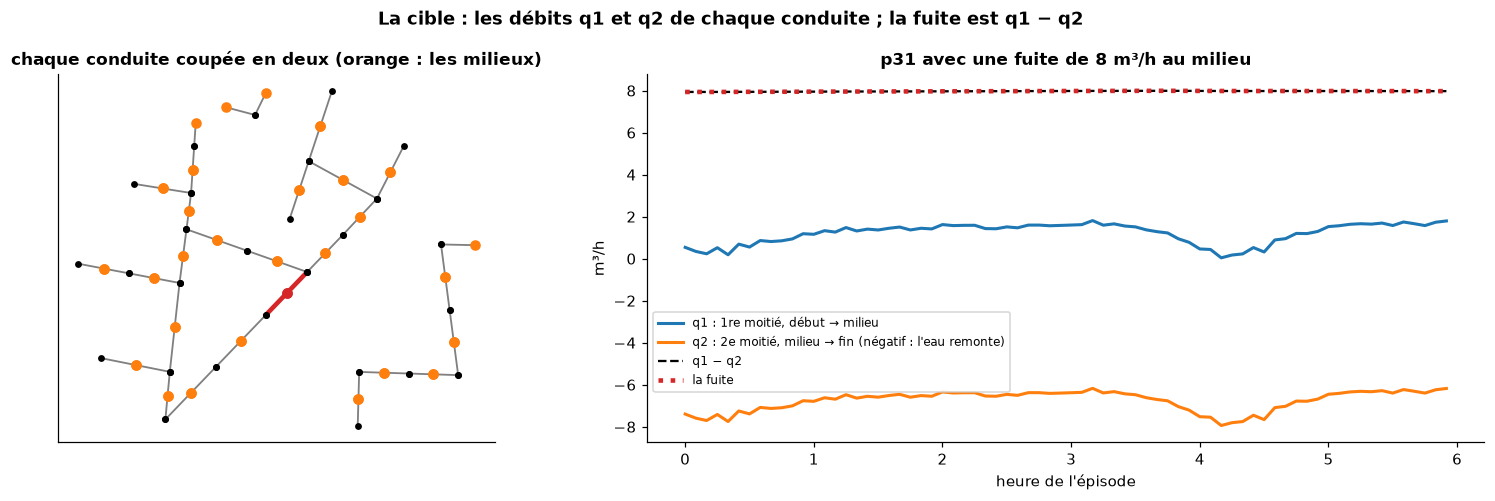

In [4]:
P.coupe_et_cible()

Ici l'eau arrive des deux côtés vers la fuite : q1 ≈ +1,5 m³/h, q2 ≈ −6,5 m³/h (le signe dit le
sens), et q1 − q2 = 8 m³/h, exactement la fuite.

Deuxième cible : pour chaque conduite, **1 si elle fuit, 0 sinon**.

## 3. Le modèle

Un réseau de neurones sur le graphe des conduites (de type GraphGPS, 190 000 paramètres).

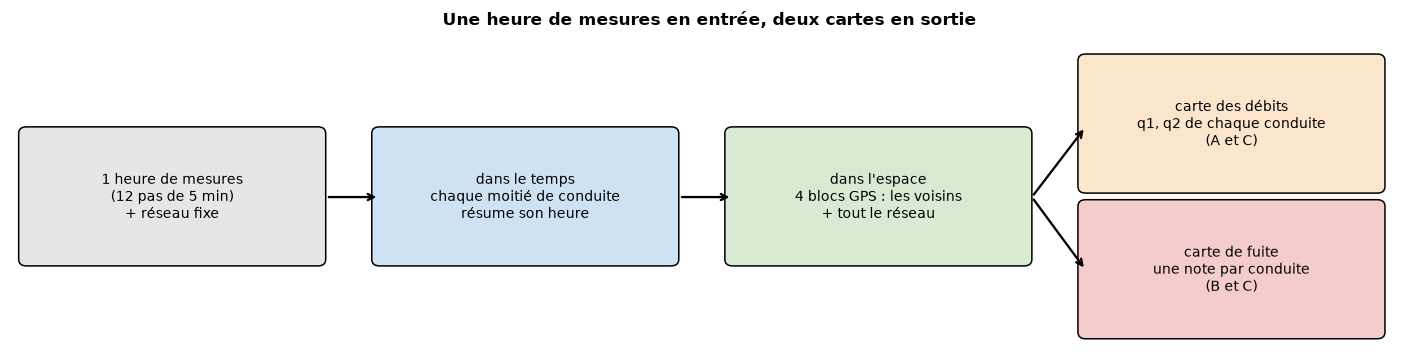

In [5]:
P.schema_du_modele()

Trois versions, même architecture ; seul ce qu'on leur demande change :

In [6]:
P.tableau_des_modeles()

,ce qu'il prédit,ce qu'il apprend à minimiser,sa carte de fuite
A,"les débits q1, q2 de chaque conduite",erreur sur les débits,le bilan q1 − q2
B,une note « fuit / ne fuit pas » par conduite,erreur sur la note (fuites pesées plus fort),la note
C (le modèle présenté),les deux,"moitié l'une, moitié l'autre","la note, ou le bilan q1 − q2"


## 4. Les données d'apprentissage

Des épisodes simulés de 6 h : une variante du réseau (rugosités, demandes, bruit des capteurs), un
jour, et 0, 1 ou 3 fuites de 2 à 20 m³/h posées au milieu de conduites tirées au hasard.
Apprentissage, validation et test n'ont ni les mêmes variantes ni les mêmes jours.

In [7]:
P.tableau_des_donnees()

fuites,0 fuite(s),1 fuite(s),3 fuite(s),épisodes
partition,,,,
"test (variantes 37–40, jours 310–362)",14,17,12,43
"apprentissage (variantes 1–32, jours 0–240)",224,224,192,640
"validation (variantes 33–36, jours 250–300)",28,28,24,80


**Suite** : carnet 2, le modèle suit-il la cible ?